In [27]:
import os
import requests
import pandas as pd
from io import BytesIO
from dotenv import load_dotenv

load_dotenv()


class APIClient:
    """Client pour récupérer les données Vélib et météo."""

    VELIB_URL = (
        "https://opendata.paris.fr/api/explore/v2.1/"
        "catalog/datasets/velib-disponibilite-en-temps-reel/"
        "exports/csv?use_labels=true"
    )

    METEO_URL = (
        "https://public-api.meteofrance.fr/public/DPObs/v2/"
        "station/infrahoraire-6m?id_station="
    )

    STATIONS_METEO_URL = (
        "https://public-api.meteofrance.fr/public/DPObs/v2/liste-stations"
    )

    CITY_DEPARTEMENT_CODE = "75"

    def __init__(self, timeout: int = 30):
        self.timeout = timeout
        self.session = requests.Session()
        self.token = os.getenv("TOKEN")
        self.dataset_url = None  # Initialisation propre

    def get_city_stations_id(self):
        response = self.session.get(
            self.STATIONS_METEO_URL,
            headers={
                "accept": "*/*",
                "apikey": self.token,
            },
            timeout=self.timeout,
        )
        response.raise_for_status()

        stations_df = pd.read_csv(
            BytesIO(response.content),
            encoding="utf-8-sig",
            sep=None,
            engine="python",
            dtype={"Id_station": str},
        )
        
        id_stations_df = stations_df[stations_df["Id_station"].str.startswith("75", na=False)]["Id_station"]

        return id_stations_df

    def get_velib_dataset(self):
        response = self.session.get(
            self.dataset_url,
            timeout=self.timeout,
        )
        response.raise_for_status()

        return pd.read_csv(
            BytesIO(response.content),
            encoding="utf-8-sig",
            sep=None,
            engine="python",
        )

    def get_meteo_dataset(self):
        if not self.token:
            raise ValueError(
                "TOKEN absent du fichier .env ou non chargé."
            )

        list_stations_id = self.get_city_stations_id()
        dataframes = []

        for station in list_stations_id:
            url = f"{self.dataset_url}{station}&format=json"

            response = self.session.get(
                url,
                headers={
                    "accept": "*/*",
                    "apikey": self.token,
                },
                timeout=self.timeout,
            )

            response.raise_for_status()
            data = pd.json_normalize(response.json())
            dataframes.append(data)

        if dataframes:
            return pd.concat(dataframes, ignore_index=True)

        return pd.DataFrame()

    def get_dataset(self, dataset_name: str) -> pd.DataFrame:
        """Récupère les données et les convertit en DataFrame."""
        if dataset_name == "velib":
            self.dataset_url = self.VELIB_URL
            dataset = self.get_velib_dataset()

        elif dataset_name == "meteo":
            self.dataset_url = self.METEO_URL
            dataset = self.get_meteo_dataset()

        else:
            raise ValueError(
                "Dataset inconnu. Choisissez 'velib' ou 'meteo'."
            )

        return dataset

    def close(self) -> None:
        self.session.close()

    def __enter__(self):
        return self

    def __exit__(self, exc_type, exc_value, traceback):
        self.close()

    @staticmethod
    def fetch_dataset(dataset: str) -> pd.DataFrame:
        with APIClient() as client:
            return client.get_dataset(dataset)

In [28]:
from dotenv import load_dotenv
import os

# Remplace cet exemple par le chemin de ton fichier
load_dotenv(
    dotenv_path=r"C:\Users\thier\OneDrive\Compta\Документы\AAAAAA\PSTB\Cours programation Python\tp1\DSB---PSTB---M2---2026-2027---09-10-2026---MARIIIIIE---PYTHON-COURS\api\.env",
    override=True
)

# Vérifier sans afficher la clé
print("TOKEN chargé :", bool(os.getenv("TOKEN")))

TOKEN chargé : True


In [29]:
with APIClient() as client:
    df_velib = client.get_dataset("velib")
print(f"Stations chargées : {len(df_velib)}")

Stations chargées : 1520


In [30]:
print(df_velib.columns.tolist())

['Identifiant station', 'Nom station', 'Station en fonctionnement', 'Capacité de la station', 'Nombre bornettes libres', 'Nombre total vélos disponibles', 'Vélos mécaniques disponibles', 'Vélos électriques disponibles', 'Borne de paiement disponible', 'Retour vélib possible', 'Actualisation de la donnée', 'Coordonnées géographiques', 'Nom communes équipées', 'Code INSEE communes équipées', 'station_opening_hours']


In [31]:
import requests

# 1. Récupération des données météo en temps réel pour Paris
url_meteo = "https://api.open-meteo.com/v1/forecast?latitude=48.8566&longitude=2.3522&current=temperature_2m,relative_humidity_2m,precipitation,weather_code"
response = requests.get(url_meteo)

if response.status_code == 200:
    data_meteo = response.json()['current']
    temp_actuelle = data_meteo['temperature_2m']
    humidite = data_meteo['relative_humidity_2m']
    pluie = data_meteo['precipitation']
    
    print("--- 🌤️ CONDITIONS MÉTÉO ACTUELLES À PARIS ---")
    print(f"🌡️ Température : {temp_actuelle}°C")
    print(f"💧 Humidité : {humidite}%")
    print(f"🌧️ Précipitations : {pluie} mm")
else:
    print("Impossible de récupérer les données météo.")

--- 🌤️ CONDITIONS MÉTÉO ACTUELLES À PARIS ---
🌡️ Température : 10.8°C
💧 Humidité : 69%
🌧️ Précipitations : 0.0 mm


In [32]:
import folium
from folium.plugins import MarkerCluster
from branca.element import Element
import requests
import pandas as pd

print("--- GÉNÉRATION DE LA CARTE AVEC MÉTÉO ET CLUSTERS ---")

# 1. Récupération de la météo en temps réel (Open-Meteo)
url_meteo = "https://api.open-meteo.com/v1/forecast?latitude=48.8566&longitude=2.3522&current=temperature_2m,relative_humidity_2m,precipitation"
response = requests.get(url_meteo)

if response.status_code == 200:
    data_meteo = response.json()['current']
    temp_actuelle = data_meteo['temperature_2m']
    humidite = data_meteo['relative_humidity_2m']
    pluie = data_meteo['precipitation']
else:
    temp_actuelle, humidite, pluie = "N/A", "N/A", "N/A"

# 2. Nettoyage des données Vélib'
df_velib['Capacité de la station'] = pd.to_numeric(df_velib['Capacité de la station'], errors='coerce')
df_velib['Nombre total vélos disponibles'] = pd.to_numeric(df_velib['Nombre total vélos disponibles'], errors='coerce')
df_velib = df_velib.dropna(subset=['Capacité de la station', 'Nombre total vélos disponibles', 'Coordonnées géographiques'])
df_velib = df_velib[df_velib['Capacité de la station'] > 0]
df_velib['taux_remplissage'] = (df_velib['Nombre total vélos disponibles'] / df_velib['Capacité de la station']) * 100

def attribuer_couleur(taux):
    if taux < 20:
        return 'red'
    elif taux < 60:
        return 'orange'
    else:
        return 'green'

df_velib['couleur'] = df_velib['taux_remplissage'].apply(attribuer_couleur)

# 3. Création de la carte avec le fond Esri
carte_paris = folium.Map(
    location=[48.8566, 2.3522], 
    zoom_start=13, 
    tiles='Esri.WorldStreetMap'
)

# 4. Ajout du module MarkerCluster
marker_cluster = MarkerCluster().add_to(carte_paris)

# 5. Ajout des stations
for idx, row in df_velib.iterrows():
    try:
        coords = str(row['Coordonnées géographiques']).split(',')
        lat, lon = float(coords[0].strip()), float(coords[1].strip())
        
        nom_station = row['Nom station']
        velos = int(row['Nombre total vélos disponibles'])
        capacite = int(row['Capacité de la station'])
        taux = row['taux_remplissage']
        couleur = row['couleur']

        folium.CircleMarker(
            location=[lat, lon],
            radius=5,
            color=couleur,
            fill=True,
            fill_color=couleur,
            fill_opacity=0.7,
            popup=f"<b>{nom_station}</b><br>Vélos : {velos}/{capacite}<br>Remplissage : {taux:.1f}%"
        ).add_to(marker_cluster)
    except Exception:
        continue

# 6. Ajout du Widget Météo HTML/CSS flottant sur la carte
html_meteo = f"""
<div style="
    position: fixed; 
    top: 15px; right: 15px; width: 210px; 
    background-color: white; border: 2px solid #ccc; z-index:9999; 
    font-size:13px; padding: 10px; border-radius: 8px; 
    box-shadow: 0 4px 6px rgba(0,0,0,0.2); font-family: sans-serif;">
    <h4 style="margin: 0 0 8px 0; color: #2c3e50;">🌤️ Météo Paris</h4>
    <b>Température :</b> {temp_actuelle}°C<br>
    <b>Humidité :</b> {humidite}%<br>
    <b>Précipitations :</b> {pluie} mm
</div>
"""
carte_paris.get_root().html.add_child(Element(html_meteo))

# 7. Sauvegarde finale
output_file = "carte_velib_paris.html"
carte_paris.save(output_file)

print(f"🎉 Carte finale générée avec succès : {output_file}")

--- GÉNÉRATION DE LA CARTE AVEC MÉTÉO ET CLUSTERS ---
🎉 Carte finale générée avec succès : carte_velib_paris.html


In [33]:
# --- CALCUL DES INDICATEURS CLÉS (KPIs) ---

total_stations = len(df_velib)
total_velos = df_velib['Nombre total vélos disponibles'].sum()
total_capacite = df_velib['Capacité de la station'].sum()
taux_moyen = df_velib['taux_remplissage'].mean()

# Comptage par catégorie de remplissage
stations_vides = len(df_velib[df_velib['taux_remplissage'] < 20])
stations_moyennes = len(df_velib[(df_velib['taux_remplissage'] >= 20) & (df_velib['taux_remplissage'] < 60)])
stations_pleines = len(df_velib[df_velib['taux_remplissage'] >= 60])

print("=== RAPPORT STATISTIQUE VÉLIB' PARIS ===")
print(f"📊 Nombre total de stations analysées : {total_stations}")
print(f"🚲 Nombre total de vélos disponibles : {total_velos:,} / {total_capacite:,}")
print(f"📈 Taux de remplissage moyen : {taux_moyen:.1f}%")
print("-" * 40)
print(f"🔴 Stations en pénurie (< 20%) : {stations_vides} ({stations_vides/total_stations*100:.1f}%)")
print(f"🟠 Stations équilibrées (20% - 60%) : {stations_moyennes} ({stations_moyennes/total_stations*100:.1f}%)")
print(f"🟢 Stations bien approvisionnées (> 60%) : {stations_pleines} ({stations_pleines/total_stations*100:.1f}%)")

=== RAPPORT STATISTIQUE VÉLIB' PARIS ===
📊 Nombre total de stations analysées : 1517
🚲 Nombre total de vélos disponibles : 17,929 / 49,957
📈 Taux de remplissage moyen : 37.1%
----------------------------------------
🔴 Stations en pénurie (< 20%) : 578 (38.1%)
🟠 Stations équilibrées (20% - 60%) : 568 (37.4%)
🟢 Stations bien approvisionnées (> 60%) : 371 (24.5%)


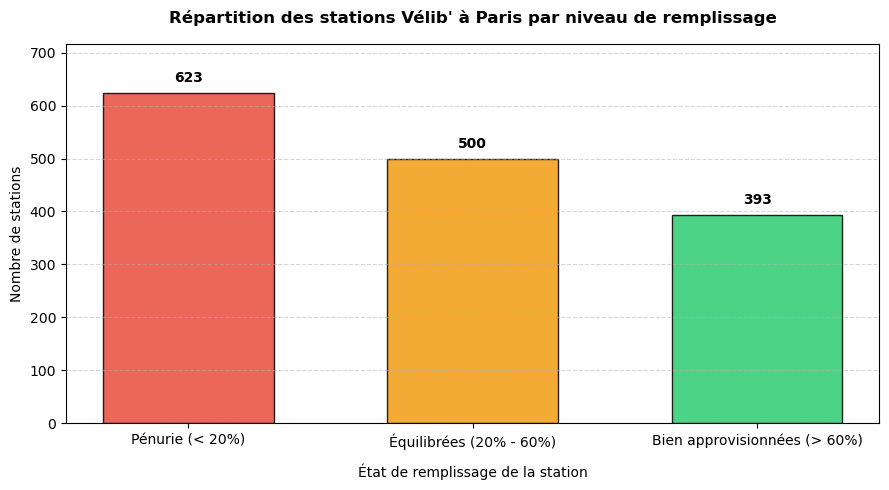

In [ ]:
import matplotlib.pyplot as plt

# Données issues de l'analyse
categories = ['Pénurie (< 20%)', 'Équilibrées (20% - 60%)', 'Bien approvisionnées (> 60%)']
valeurs = [623, 500, 393]
couleurs = ['#e74c3c', '#f39c12', '#2ecc71'] # Rouge, Orange, Vert professionnels


plt.figure(figsize=(9, 5))
bars = plt.bar(categories, valeurs, color=couleurs, width=0.6, edgecolor='black', alpha=0.85)

plt.title("Répartition des stations Vélib' à Paris par niveau de remplissage", fontsize=12, fontweight='bold', pad=15)
plt.xlabel("État de remplissage de la station", fontsize=10, labelpad=10)
plt.ylabel("Nombre de stations", fontsize=10)


for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 15, f"{yval}", ha='center', va='bottom', fontweight='bold', fontsize=10)


plt.ylim(0, max(valeurs) * 1.15)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()

plt.show()